In [1]:
import os

if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score
from xgboost import XGBClassifier

from idxlab.clean import clean_ticker_data
from idxlab.config import load_config
from idxlab.data import DataLoader
from idxlab.evaluation import (
    bootstrap_auc_ci,
    evaluate_classifier,
    paired_bootstrap_auc_diff,
)
from idxlab.logging_setup import setup_logging
from idxlab.split import build_dataset, time_based_split
from idxlab.backtest import proba_to_signal, run_backtest
from idxlab.metrics import exposure_matched_return, summarize
from idxlab.evaluation import bootstrap_auc_ci, evaluate_classifier
from idxlab.walkforward import walk_forward_proba

Path("docs/results").mkdir(parents=True, exist_ok=True)
Path("docs/figures").mkdir(parents=True, exist_ok=True)

cfg = load_config()
setup_logging(cfg.log_level)
loader = DataLoader.from_config(cfg)
raw = loader.load_all()

09:45:59 | INFO     | idxlab.data | Cache hit for BBCA.JK (data\raw\BBCA_JK.parquet)
09:45:59 | INFO     | idxlab.data | Cache hit for BBRI.JK (data\raw\BBRI_JK.parquet)
09:45:59 | INFO     | idxlab.data | Cache hit for TLKM.JK (data\raw\TLKM_JK.parquet)
09:45:59 | INFO     | idxlab.data | Cache hit for ASII.JK (data\raw\ASII_JK.parquet)
09:45:59 | INFO     | idxlab.data | Cache hit for UNVR.JK (data\raw\UNVR_JK.parquet)


In [2]:
best = json.loads(Path("docs/results/day16_best_params.json").read_text(encoding="utf-8"))

# Order matters: simplest first. This is the challenge order in the protocol.
candidates = {
    "logreg": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(max_iter=1000, random_state=42)),
    ]),
    "rf_default": RandomForestClassifier(
        n_estimators=300, max_depth=5, min_samples_leaf=10, random_state=42, n_jobs=-1
    ),
    "rf_tuned": RandomForestClassifier(**best["rf"]),
    "xgb_default": XGBClassifier(
        n_estimators=300, max_depth=3, learning_rate=0.05,
        subsample=0.8, colsample_bytree=0.8,
        eval_metric="logloss", random_state=42, n_jobs=1,
    ),
    "xgb_tuned": XGBClassifier(**best["xgb"]),
}
dummy = DummyClassifier(strategy="most_frequent")  # reference only, not a candidate

chosen = "logreg"                 
model = candidates[chosen]

In [3]:
ohlcv = clean_ticker_data(raw["BBCA.JK"])
dataset = build_dataset(ohlcv)
split = time_based_split(dataset)
feature_cols = [c for c in dataset.columns if c not in ("forward_return", "direction")]

dev = pd.concat([split.train, split.val])      
returns = ohlcv["Close"].pct_change()
PARAMS = dict(train_size=250, step=20, gap=1, rolling=True)
print(len(dev), "baris dev;", len(split.val), "baris val;", len(split.test), "baris test (tidak dipakai)")

722 baris dev; 127 baris val; 128 baris test (tidak dipakai)


In [4]:
ROOT = Path.cwd() if (Path.cwd() / "docs").exists() else Path.cwd().parent
RESULT_PATH = ROOT / "docs" / "results" / "day24_test_results.csv"

if RESULT_PATH.exists():
    raise RuntimeError("Test set was already evaluated. Do not run this cell again.")

dev = pd.concat([split.train, split.val])                   
test = split.test

all_models = {"dummy": dummy, **candidates}
names = list(dict.fromkeys(["dummy", "logreg", chosen])) 

X_dev, y_dev = dev[feature_cols], dev["direction"].astype(int)
X_test, y_test = test[feature_cols], test["direction"].astype(int)

test_proba, test_pred = {}, {}
for name in names:
    fitted = clone(all_models[name]).fit(X_dev, y_dev)              
    test_proba[name] = pd.Series(fitted.predict_proba(X_test)[:, 1], index=test.index)   
    test_pred[name] = pd.Series(fitted.predict(X_test), index=test.index)

r_test = returns.loc[test.index]
rows, dailies = {}, {}
for name in names:
    lo, hi = bootstrap_auc_ci(y_test, test_proba[name])
    cls = evaluate_classifier(y_test, test_pred[name], test_proba[name])
    daily = run_backtest(r_test, proba_to_signal(test_proba[name], 0.5))
    dailies[name] = daily
    bt = summarize(daily)
    rows[name] = {
        **cls,
        "auc_ci_low": lo,
        "auc_ci_high": hi,
        "bt_cum_return": bt["cum_return"],
        "bt_sharpe": bt["sharpe"],
        "bt_max_dd": bt["max_drawdown"],
        "bt_n_trades": bt["n_trades"],
        "bt_exposure": bt["exposure"],
        "bench_cum_return": bt["bench_cum_return"],
        "bench_max_dd": bt["bench_max_drawdown"],
        "bench_matched": exposure_matched_return(r_test, bt["exposure"]),                
    }

test_results = pd.DataFrame.from_dict(rows, orient="index")
RESULT_PATH.parent.mkdir(parents=True, exist_ok=True)
test_results.round(4).to_csv(RESULT_PATH)                  
print(len(test), "hari test,", test.index.min().date(), "->", test.index.max().date())
test_results.round(3).T

128 hari test, 2026-02-13 -> 2026-08-28


,dummy,logreg
accuracy,0.562,0.586
precision,0.000,0.537
recall,0.000,0.393
f1,0.000,0.454
roc_auc,0.500,0.620
auc_ci_low,0.500,0.524
auc_ci_high,0.500,0.717
bt_cum_return,0.000,0.120
bt_sharpe,NaN,0.943
bt_max_dd,0.000,-0.126


logreg: test ROC-AUC 0.620, 95% CI [0.524, 0.717]
Interval excludes 0.5: True


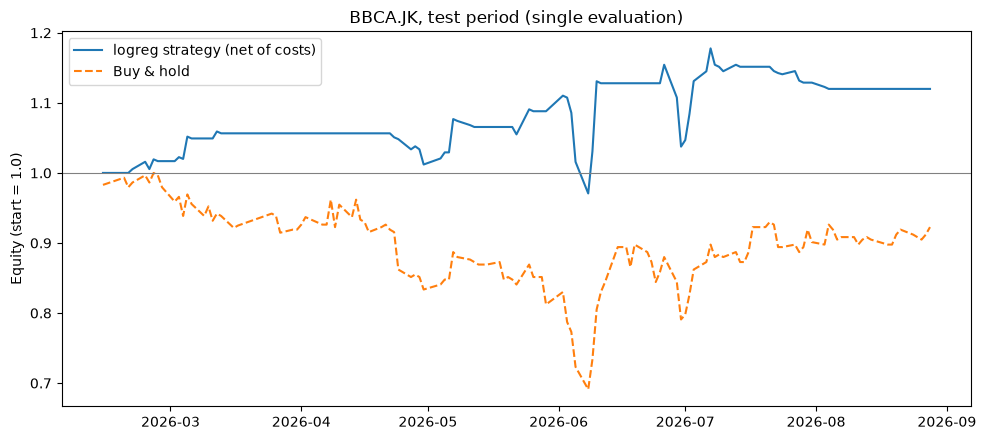

In [5]:
lo, hi = test_results.loc[chosen, "auc_ci_low"], test_results.loc[chosen, "auc_ci_high"]
auc = test_results.loc[chosen, "roc_auc"]
print(f"{chosen}: test ROC-AUC {auc:.3f}, 95% CI [{lo:.3f}, {hi:.3f}]")
print("Interval excludes 0.5:", lo > 0.5)              

d = dailies[chosen]
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(d.index, d["equity"], label=f"{chosen} strategy (net of costs)")
ax.plot(d.index, d["benchmark_equity"], linestyle="--", label="Buy & hold")
ax.axhline(1.0, color="grey", linewidth=0.8)
ax.set_title("BBCA.JK, test period (single evaluation)")
ax.set_ylabel("Equity (start = 1.0)")
ax.legend()
plt.tight_layout()
(ROOT / "docs" / "figures").mkdir(parents=True, exist_ok=True)
plt.savefig(ROOT / "docs" / "figures" / "day24_test_equity.png", dpi=150)
plt.show()